# Stage 0.3: *Cognitive Reframing Dataset* preprocessing

Source file: `reframing_dataset.csv` (600 records)

**Output.** `processed/cognitive_reframing.csv` — one row per reframe, with a shared `thought_id` linking reframes of the same thought, a `dominant_label` extracted from the first element of the `thinking_traps_addressed` list, and an `all_labels` column storing the full label list as a JSON string.

**Pipeline:**

1. Load the CSV and verify its structure.
2. Parse the `thinking_traps_addressed` field into a list of labels.
3. Identify the dominant label (first element of the list).
4. Assign a `thought_id` shared by reframes of the same thought.
5. Filter records where `thought` or `reframe` is under 10 characters.
6. Export the processed CSV and log all preprocessing decisions.

## Step 1: Imports and configuration

In [17]:
import json
import re
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

INPUT_PATH = Path("./datasets/reframing_dataset.csv")
OUTPUT_DIR = Path("processed")
OUTPUT_PATH = OUTPUT_DIR / "cognitive_reframing.csv"
LOG_PATH = OUTPUT_DIR / "cognitive_reframing_preprocessing_log.json"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Minimum character length for thought and reframe (per Section 0.3 step 5).
MIN_TEXT_LENGTH = 5

# A dictionary that records every preprocessing decision for reproducibility
# and for the Section 3.6 write-up of the thesis.
log = {}

## Step 2: Load the raw CSV and verify its structure

Each record should have (situation, distorted thought, reframed thought)

In [18]:
df_raw = pd.read_csv(INPUT_PATH)

expected_columns = {"situation", "thought", "reframe", "thinking_traps_addressed"}
assert set(df_raw.columns) == expected_columns, (
    f"Unexpected columns: {set(df_raw.columns)}"
)

log["raw_row_count"] = len(df_raw)
log["raw_columns"] = list(df_raw.columns)

print(f"Loaded {len(df_raw)} records with columns {list(df_raw.columns)}.")
df_raw.head()

Loaded 600 records with columns ['situation', 'thought', 'reframe', 'thinking_traps_addressed'].


,situation,thought,reframe,thinking_traps_addressed
0,A Roomate of mine stole my comptuer,Someone I trusted stole something valuable of ...,"My roommate stole something of mine, and I wil...",emotional reasoning
1,A Roomate of mine stole my comptuer,Someone I trusted stole something valuable of ...,While I would like there to be consequences fo...,emotional reasoning
2,"A few days ago, I got angry at my husband's gr...",She doesn't respect me.,She is older and may have been tired,overgeneralizing
3,"A few days ago, I got angry at my husband's gr...",She doesn't respect me.,"I felt disrespected by her actions, but that d...",overgeneralizing
4,A friend who is a recent widower has started d...,My friend is ignoring his recently-deceased wife.,Maybe my friend is in a healthy spot to date n...,disqualifying the positive


## Step 3: Whitespace and unicode normalisation

The same normalisation is applied as in step 0.1 (*TherapistQA*) for consistency across datasets: unicode is normalised to NFKC, multiple spaces are collapsed, and leading or trailing whitespace is stripped. The original fields are preserved; the cleaned versions replace them in the processed CSV.

### Cleaning policy: what is normalised and what is preserved

An inspection of the raw file was carried out before the cleaning step was fixed. The findings motivate the policy below.

**Normalised:**

- *Multiple consecutive spaces* inside the `situation` and `reframe` fields (78 occurrences across 600 records) -> collapsed to a single space. These are typing artefacts and carry no information.
- *Leading and trailing whitespace* -> stripped.
- *Line-ending variants* (`\r\n`, `\r`) -> normalised to `\n` for consistency with the other preprocessing notebooks.
- *Unicode compatibility forms* -> normalised via NFKC. In practice this only affects edge cases; the curly characters that appear in this dataset (right single quotation mark `’`, left double quotation mark `“`, horizontal ellipsis `…`) are canonical code points and are preserved unchanged by NFKC.

**Preserved (intentionally not cleaned):**

- *CSV-escaped double quotes* in a handful of `situation` and `reframe` values (for example row 460, `"...something for me" even if..."`). The raw file escapes internal double quotes by doubling them (`""`), which is standard CSV behaviour; pandas un-escapes them on load. The resulting text contains scare quotes the annotators wrote deliberately — for example `"incompetent"`, `"selfish"`, `"never"` - and removing them would distort meaning.
- *Curly apostrophes and quotation marks* (`isn’t`, `“sleep forever”`) - legitimate typography in human-written text.
- *Ellipses* (`…`) - meaningful punctuation used by the annotators to signal trailing thought.
- *Case of the free-text fields* - not lowercased, as modern subword tokenisers handle case themselves and the classifier loses useful cues when case is stripped. Only the label field is lowercased, for deduplication purposes.

In [19]:
def normalise_text(text: str) -> str:
    """Normalise whitespace and unicode in a free-text field."""
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"[ \t]+", " ", text)
    return text.strip()


df = df_raw.copy()
for column in ["situation", "thought", "reframe", "thinking_traps_addressed"]:
    df[column] = df[column].apply(normalise_text)

## Step 4: Parse `thinking_traps_addressed` into a list of labels

The field stores either a single label or multiple labels separated by commas. The string is split on commas and each element is trimmed and lowercased. Labels that evaluate to the empty string after trimming are discarded.

In [20]:
def parse_labels(label_field: str) -> list[str]:
    """Split a comma-separated label string into a lowercase list of labels."""
    if not isinstance(label_field, str) or not label_field.strip():
        return []
    parts = [part.strip().lower() for part in label_field.split(",")]
    return [part for part in parts if part]


df["all_labels_list"] = df["thinking_traps_addressed"].apply(parse_labels)
df["n_labels"] = df["all_labels_list"].apply(len)

multi_label_share = (df["n_labels"] > 1).mean() * 100
log["multi_label_share_percent"] = round(multi_label_share, 2)
log["label_count_distribution"] = (
    df["n_labels"].value_counts().sort_index().to_dict()
)

print(f"Multi-label records: {(df['n_labels'] > 1).sum()} of {len(df)} "
      f"({multi_label_share:.1f}%).")
print("Distribution of labels per record:")
print(df["n_labels"].value_counts().sort_index())

Multi-label records: 198 of 600 (33.0%).
Distribution of labels per record:
n_labels
1    402
2    108
3     57
4     13
5     10
6      4
7      4
8      2
Name: count, dtype: int64


## Step 5: Identify the dominant label

For records with multiple labels, the first element of the list is taken as the dominant label. The full list is preserved in `all_labels` and exported as a JSON-serialised string for downstream use.

In [21]:
df["dominant_label"] = df["all_labels_list"].apply(
    lambda labels: labels[0] if labels else ""
)
df["all_labels"] = df["all_labels_list"].apply(json.dumps)

dominant_counts = df["dominant_label"].value_counts()
log["dominant_label_distribution"] = dominant_counts.to_dict()

print("Dominant label distribution:")
print(dominant_counts)

Dominant label distribution:
dominant_label
negative feeling or emotion    80
labeling                       70
overgeneralizing               61
mind reading                   57
all-or-nothing thinking        57
fortune telling                56
personalizing                  55
disqualifying the positive     35
catastrophizing                35
emotional reasoning            31
none                           18
should statements              18
blaming                        17
comparing and despairing        8
magnification                   2
Name: count, dtype: int64


In [22]:
all_label_counter = Counter(label for labels in df["all_labels_list"] for label in labels)
log["all_label_counts"] = dict(all_label_counter.most_common())

print("Cumulative counts across all labels (a record with k labels contributes k times):")
for label, count in all_label_counter.most_common():
    print(f"  {label}: {count}")

Cumulative counts across all labels (a record with k labels contributes k times):
  negative feeling or emotion: 151
  overgeneralizing: 107
  labeling: 102
  all-or-nothing thinking: 99
  personalizing: 98
  fortune telling: 78
  mind reading: 71
  catastrophizing: 68
  emotional reasoning: 43
  disqualifying the positive: 40
  blaming: 34
  should statements: 22
  none: 19
  magnification: 15
  comparing and despairing: 12


## Step 6: Assign a shared `thought_id` to rows that share the same thought

The dataset contains 286 unique thoughts spread over 600 rows: 278 thoughts appear twice, 6 appear four times, and 2 appear ten times. Multi-occurrence rows correspond to independent reframes of the same thought, and several of them are also assigned different dominant labels. A `thought_id` is assigned by deterministic hashing of the cleaned thought text so that every reframe of the same thought can be grouped together in later analysis.

In [23]:
unique_thoughts = df["thought"].drop_duplicates().reset_index(drop=True)
thought_to_id = {text: idx for idx, text in enumerate(unique_thoughts)}
df["thought_id"] = df["thought"].map(thought_to_id)

reframes_per_thought = df.groupby("thought_id").size()
log["unique_thought_count"] = int(df["thought_id"].nunique())
log["reframes_per_thought_distribution"] = (
    reframes_per_thought.value_counts().sort_index().to_dict()
)

print(f"Unique thoughts: {df['thought_id'].nunique()}")
print("Reframes per thought (distribution):")
print(reframes_per_thought.value_counts().sort_index())

Unique thoughts: 286
Reframes per thought (distribution):
2     278
4       6
10      2
Name: count, dtype: int64


## Step 7: Length filter

Records in which the cleaned `thought` or `reframe` field is shorter than ten characters are reviewed but it is decided to keep them since they are also valid examples.

In [24]:
df["thought_length"] = df["thought"].str.len()
df["reframe_length"] = df["reframe"].str.len()
df["situation_length"] = df["situation"].str.len()

too_short_mask = (df["thought_length"] < MIN_TEXT_LENGTH) | (
    df["reframe_length"] < MIN_TEXT_LENGTH
)

log["short_record_count"] = int(too_short_mask.sum())
log["short_record_min_length"] = MIN_TEXT_LENGTH
log["row_count"] = int(len(df))

print(f"Flagged {int(too_short_mask.sum())} records with thought or reframe shorter "
      f"than {MIN_TEXT_LENGTH} characters. All records are kept in the output.")
if too_short_mask.any():
    print("Flagged records:")
    display(df.loc[too_short_mask, ["situation", "thought", "reframe",
                                     "thought_length", "reframe_length"]])

Flagged 0 records with thought or reframe shorter than 5 characters. All records are kept in the output.


## Step 8: Descriptive statistics

Summary statistics over the cleaned dataset.

In [25]:
length_summary = df[["situation_length", "thought_length", "reframe_length"]].describe()
log["length_summary"] = length_summary.round(2).to_dict()
length_summary

,situation_length,thought_length,reframe_length
count,600.000000,600.000000,600.000000
mean,98.130000,40.266667,114.793333
std,84.637219,29.161496,52.970719
min,8.000000,8.000000,14.000000
25%,49.000000,21.000000,75.000000
50%,72.500000,32.000000,105.000000
75%,116.500000,51.000000,145.250000
max,469.000000,192.000000,282.000000


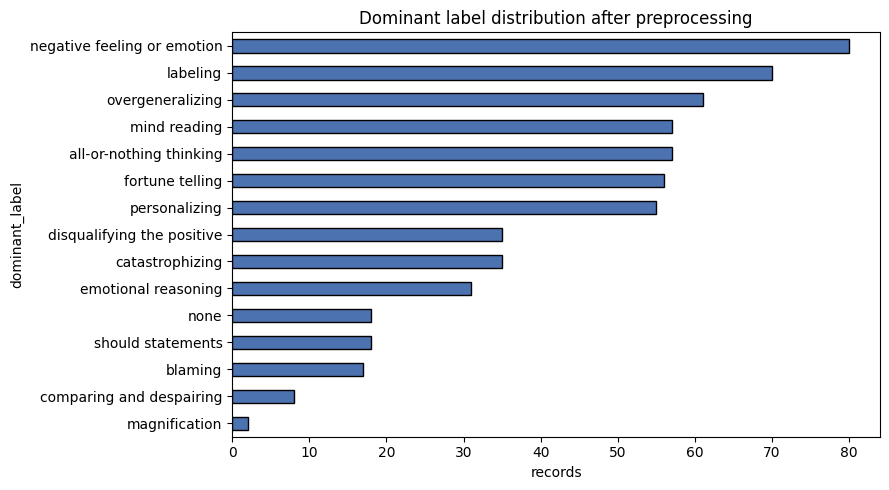

In [26]:
fig, ax = plt.subplots(figsize=(9, 5))
dominant_counts_clean = df["dominant_label"].value_counts()
dominant_counts_clean.plot(kind="barh", ax=ax, color="#4C72B0", edgecolor="black")
ax.invert_yaxis()
ax.set_xlabel("records")
ax.set_title("Dominant label distribution after preprocessing")
plt.tight_layout()
plt.show()

## Step 9: Finalise and export

The final CSV retains the following columns, in the order specified by the master plan:

- `thought_id` — integer identifier shared by reframes of the same thought;
- `situation` — the cleaned context in which the thought occurred;
- `thought` — the cleaned distorted thought;
- `reframe` — the cleaned reframed thought;
- `dominant_label` — the first label in the thinking-trap list (lowercase);
- `all_labels` — the full label list encoded as a JSON string.

In [27]:
output_columns = [
    "thought_id",
    "situation",
    "thought",
    "reframe",
    "dominant_label",
    "all_labels",
    "situation_length",
    "thought_length",
    "reframe_length",
]
df_out = df[output_columns].copy()
df_out.to_csv(OUTPUT_PATH, index=False)

log["output_path"] = str(OUTPUT_PATH)
log["output_row_count"] = int(len(df_out))
log["output_columns"] = output_columns

print(f"Wrote {len(df_out)} rows to {OUTPUT_PATH}.")
df_out.head()

Wrote 600 rows to processed/cognitive_reframing.csv.


,thought_id,situation,thought,reframe,dominant_label,all_labels,situation_length,thought_length,reframe_length
0,0,A Roomate of mine stole my comptuer,Someone I trusted stole something valuable of ...,"My roommate stole something of mine, and I wil...",emotional reasoning,"[""emotional reasoning""]",35,92,94
1,0,A Roomate of mine stole my comptuer,Someone I trusted stole something valuable of ...,While I would like there to be consequences fo...,emotional reasoning,"[""emotional reasoning""]",35,92,101
2,1,"A few days ago, I got angry at my husband's gr...",She doesn't respect me.,She is older and may have been tired,overgeneralizing,"[""overgeneralizing""]",158,23,36
3,1,"A few days ago, I got angry at my husband's gr...",She doesn't respect me.,"I felt disrespected by her actions, but that d...",overgeneralizing,"[""overgeneralizing""]",158,23,84
4,2,A friend who is a recent widower has started d...,My friend is ignoring his recently-deceased wife.,Maybe my friend is in a healthy spot to date n...,disqualifying the positive,"[""disqualifying the positive""]",52,49,184


In [28]:
with open(LOG_PATH, "w", encoding="utf-8") as fh:
    json.dump(log, fh, indent=2, ensure_ascii=False)
print(f"Wrote preprocessing log to {LOG_PATH}.")

Wrote preprocessing log to processed/cognitive_reframing_preprocessing_log.json.
